# Notebook 04: Aspect extraction

Aspect = the part of the service a sentence talks about (login, fees, speed ...). This notebook builds the three
pieces of the aspect component described in the proposal:

1. a curated multilingual seed lexicon (English + Shona/Ndebele + Shona-ised English)
2. widened with word embeddings (FastText trained on our own corpus, reviewed by hand)
3. refined with dependency parsing, which finds which words of a sentence express the opinion about each aspect

Its accuracy is measured against the hand-labelled gold set in notebook 06.

In [1]:
# Setup
import sys, warnings
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from absa.setup import ensure_resources
from absa import viz
ensure_resources()
viz.use_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

In [2]:
import json
from absa.aspects import AspectLexicon, SEED_FILE, EXPANDED_FILE
from absa.data import load_reviews, load_sentences

reviews = load_reviews()
sentences = load_sentences()
seed = AspectLexicon(use_expansion=False)

## 1. The seed lexicon

Fourteen aspects. Each is tagged as app-level (controlled by the software: login, speed, updates ...) or
service-level (controlled by the company: fees, support, transfers ...). Notebook 07 uses this split as a sanity
check on the old-vs-new EcoCash comparison: if the analysis works, *service* aspects should be similar for both apps
(same company, same tariffs) while *app* aspects can differ.

In [3]:
spec = {k: v for k, v in json.load(open(SEED_FILE, encoding="utf-8")).items() if not k.startswith("_")}
pd.DataFrame([{"aspect": a, "name": s["name"], "level": s["level"], "terms": len(s["terms"]),
               "local terms": len(s["local"]), "examples": ", ".join(s["terms"][:6])}
              for a, s in spec.items()]).set_index("aspect")

,name,level,terms,local terms,examples
aspect,,,,,
login,Login & access,app,47,4,"login, log in, logging in, log on, signin, sign in"
transactions,Sending & receiving money,service,44,8,"send money, sending money, send, sending, sent, transfer"
payments,Payments & purchases,service,32,0,"pay, paying, paid, payment, bill, bills"
fees,Charges & fees,service,32,3,"charge, charges, charged, charging, fee, fees"
balance,Balance & records,app,22,0,"balance, balance enquiry, balance inquiry, statement, statements, mini statement"
performance,Speed & reliability,app,61,14,"slow, slower, slowest, slowly, fast, faster"
updates,Updates & installation,app,31,4,"update, updates, updated, updating, upgrade, upgraded"
connectivity,Network & data,service,19,2,"network, internet, wifi, wi fi, data, mobile data"
usability,Ease of use & design,app,41,2,"easy, easier, easiest, easily, simple, simpler"


Design choices worth noting:
* Terms are written in cleaned form, so one spelling covers many (*doesn't open* -> `not open`).
* Ambiguous words were removed after reading matches: *rate* ("rate this app"), *till* ("till now"),
  *phone* (too generic), *look* ("looks like"), *call* ("video call").
* An exclusion rule stops *"it sends the OTP"* being counted as a money transfer.
* Local terms, e.g. `chakadhakwa` (literally *it is drunk* = malfunctioning), `haishande` (*it doesn't work*),
  `kusenda` (*to send*), `kuswiper` (*to swipe*), `nyore` (*easy*), `akusebenzi` (Ndebele: *it doesn't work*).

In [4]:
demo = ["I never receive the OTP", "It sends the OTP but the keyboard disappears",
        "Charges are too high", "chakadhakwa app iyi", "asi itai kuti tiwane kuswiper",
        "Makes transacting a lot easier and faster", "Rate this app 5 stars", "My sim card is roaming"]
from absa.text import clean
pd.DataFrame({"sentence": demo, "aspects": [seed.tag(clean(s)) for s in demo]})

,sentence,aspects
0,I never receive the OTP,[login]
1,It sends the OTP but the keyboard disappears,[login]
2,Charges are too high,[fees]
3,chakadhakwa app iyi,[performance]
4,asi itai kuti tiwane kuswiper,[cards]
5,Makes transacting a lot easier and faster,"[transactions, usability, performance]"
6,Rate this app 5 stars,[]
7,My sim card is roaming,[]


## 2. FastText embeddings trained on the corpus

Pre-trained English embeddings know nothing about *otp*, *zesa* or *kusenda*. FastText builds each word's vector
from its character n-grams, so rare spellings and Shona-ised verbs get vectors close to their standard forms.

Two models are trained (both unsupervised, no labels used):
* `fasttext_all.model`: all reviews, used only for lexicon expansion (a resource reviewed by hand)
* `fasttext_train.model`: the training subset only, used as classifier features in notebook 05, so nothing from the
  test sets leaks into the model

In [5]:
from absa.embeddings import train_fasttext, expansion_candidates, FASTTEXT_ALL_FILE, FASTTEXT_FILE

ft_all = train_fasttext(reviews["clean"].tolist())
ft_all.save(str(FASTTEXT_ALL_FILE))
ft_train = train_fasttext(reviews.loc[reviews["subset"] == "train", "clean"].tolist())
ft_train.save(str(FASTTEXT_FILE))
print(f"vocabulary: all={len(ft_all.wv):,} words, train-only={len(ft_train.wv):,} words")

vocabulary: all=2,196 words, train-only=1,495 words


In [6]:
probe = ["otp", "charges", "crash", "kusenda", "convinient", "update", "balance", "chakadhakwa"]
pd.DataFrame({w: [f"{n} ({s:.2f})" for n, s in ft_all.wv.most_similar(w, topn=6)] for w in probe})

,otp,charges,crash,kusenda,convinient,update,balance,chakadhakwa
0,otps (0.71),charge (0.87),crashes (0.85),send (0.69),convince (0.89),updated (0.81),balances (0.89),rakadhakwa (0.98)
1,keyboard (0.64),charged (0.78),crashing (0.83),sender (0.68),convinience (0.84),updates (0.75),check (0.67),chiapp (0.87)
2,inputs (0.62),charging (0.76),trash (0.79),friend (0.67),convenient (0.81),updating (0.73),enquiry (0.60),hachisi (0.86)
3,verification (0.60),enquiries (0.65),trashy (0.69),sends (0.67),inconvinience (0.71),late (0.57),enquiries (0.59),ichi (0.85)
4,answers (0.60),enquiry (0.62),crushes (0.66),splendid (0.67),inconvenient (0.68),date (0.57),inquiry (0.59),ichii (0.84)
5,input (0.60),hides (0.61),utterly (0.65),resend (0.64),brilliant (0.68),february (0.55),refresh (0.59),chi (0.82)


Two kinds of neighbour appear, and both matter for this corpus:
* meaning: `otp` -> *keyboard*, *inputs*, *verification* (the OTP keyboard bug: the code arrives but the keyboard will not open)
* spelling (from character n-grams): `kusenda` -> *send, sends, sending*; `convinient` -> *convenient, convinience*;
  `crash` -> *crashes, crashing*. Useful for typos, but it also produces look-alikes with a different meaning
  (`crash` -> *trash*). This is why the candidates are reviewed by hand rather than accepted automatically.

## 3. Lexicon expansion

In [7]:
cands = expansion_candidates(ft_all, seed, reviews["clean"].tolist())
expanded_spec = json.load(open(EXPANDED_FILE, encoding="utf-8"))
accepted = expanded_spec["accepted"]
flat = {w for v in accepted.values() for w in v}
cands["accepted"] = cands["candidate"].isin(flat)
print(f"{len(cands)} candidates proposed, {cands['accepted'].sum()} accepted directly "
      f"({sum(len(v) for v in accepted.values())} terms added in total)")
cands.sort_values("score", ascending=False).groupby("aspect").head(6).sort_values(["aspect", "score"],
                                                                                  ascending=[True, False])

425 candidates proposed, 46 accepted directly (50 terms added in total)


,aspect,candidate,n_seeds,mean_sim,freq,score,accepted
0,balance,state,2,0.856933,3,0.941437,False
1,balance,shot,2,0.784601,4,0.861973,False
2,balance,status,2,0.782921,3,0.860126,False
3,balance,balances,2,0.771573,8,0.847660,False
4,balance,drawback,2,0.679284,3,0.746269,False
...,...,...,...,...,...,...,...
354,usability,fabulous,9,0.610889,4,1.406624,False
355,usability,convinience,5,0.703258,5,1.260070,True
356,usability,inconvinience,4,0.778429,3,1.252833,True
357,usability,brilliant,6,0.636996,10,1.239536,False


In [8]:
pd.Series({a: ", ".join(v) for a, v in accepted.items()}, name="accepted terms").to_frame()

,accepted terms
balance,confirmation
cards,"master card, unblock, physical card"
compatibility,"galaxy, detected"
login,"registered, identification, activating, deactivate, deactivated, finger, validation, recognise, recognised"
payments,"token, prepaid, scanner, bundle"
performance,"fail, crushing, crushes, responsive, functioning, closes, stopping, refuses, dependable"
security,secured
support,"complaining, assist, assisted, contacted, employees"
transactions,"transactional, recipient"
updates,"reinstalling, installation, downgrade, outdated"


The accepted terms are mostly spelling variants (*crushing* = crashing, *convinient*, *easly*), word forms
the seed list missed (*activating*, *reinstalling*, *registered*), and domain words (*token* for ZESA tokens,
*prepaid*, *downgrade*). Rejected candidates were look-alikes (*trash*, *flow*) or generic words (*check*, *view*, *show*).

## 4. Coverage

In [9]:
full = AspectLexicon(use_expansion=True)
sent = sentences.drop_duplicates("sent_id").copy()
sent["seed"] = sent["sentence_clean"].map(seed.tag)
sent["full"] = sent["sentence_clean"].map(full.tag)
print(f"sentences with an aspect: seed lexicon {(sent['seed'].str.len() > 0).mean():.1%}  ->  "
      f"after expansion {(sent['full'].str.len() > 0).mean():.1%}")
long_ = sent["sentence"].str.split().str.len() > 3
print(f"sentences longer than 3 words with an aspect: {(sent.loc[long_, 'full'].str.len() > 0).mean():.1%}")

sentences with an aspect: seed lexicon 46.3%  ->  after expansion 47.8%
sentences longer than 3 words with an aspect: 66.7%


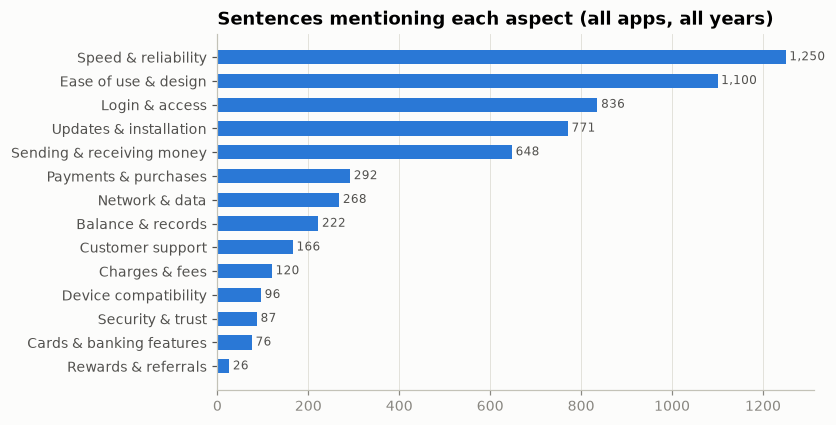

In [10]:
counts = pd.Series([a for l in sent["full"] for a in l]).value_counts()
names = counts.index.map(full.name)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(names, counts.values, color=viz.BLUE, height=0.6)
for i, v in enumerate(counts.values):
    ax.text(v + 8, i, f"{v:,}", va="center", fontsize=8, color=viz.INK_2)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_title("Sentences mentioning each aspect (all apps, all years)")
viz.save(fig, "04_aspect_frequency")
plt.show()

Speed & reliability, ease of use, login and updates dominate: these are *app* problems, consistent with
the review sample read in notebook 02 (three of fifteen were about login).

## 5. Opinion scope with dependency parsing

A sentence can hold opposite opinions on two aspects. Three ways of deciding *which words* express the opinion about
each aspect are implemented in `src/absa/scope.py` and compared on the gold set in notebook 06:

* sentence: the whole sentence
* clause: split at contrast words (*but, however, asi, kodwa*)
* dependency: walk up the parse tree from the aspect word to the clause that governs it, and keep that clause only

In [11]:
from absa.scope import scopes_for
examples = ["The app is great but the charges are too high",
            "Easy to use and sending money is fast",
            "after the update it is not opening and customer care is not helping",
            "hmmm panhau dze limit apa asi the app is quite fast"]
rows = []
for e in examples:
    c = clean(e); m = full.find(c)
    for strategy in ("sentence", "clause", "dependency"):
        for match, scope in zip(m, scopes_for(c, m, strategy)):
            rows.append({"sentence": e, "aspect": match.aspect, "strategy": strategy, "scope": scope})
pd.DataFrame(rows).pivot_table(index=["sentence", "aspect"], columns="strategy", values="scope", aggfunc="first")

strategy                                                                                                                                       clause  \
sentence                                                            aspect                                                                              
Easy to use and sending money is fast                               performance                                 easy to use and sending money is fast   
                                                                    transactions                                easy to use and sending money is fast   
                                                                    usability                                   easy to use and sending money is fast   
The app is great but the charges are too high                       fees                                                     the charges are too high   
after the update it is not opening and customer care is not helping performance   after the update it is not opening and customer care is not helping   
                                                                    support       after the update it is not opening and customer care is not helping   
                                                                    updates       after the update it is not opening and customer care is not helping   
hmmm panhau dze limit apa asi the app is quite fast                 performance                                                 the app is quite fast   
                                                                    transactions                                             hmm panhau dze limit apa   

strategy                                                                                                                                   dependency  \
sentence                                                            aspect                                                                              
Easy to use and sending money is fast                               performance                                 easy to use and sending money is fast   
                                                                    transactions                                                        sending money   
                                                                    usability                                   easy to use and sending money is fast   
The app is great but the charges are too high                       fees                                                     the charges are too high   
after the update it is not opening and customer care is not helping performance                                   it is not opening and customer care   
                                                                    support                                       it is not opening and customer care   
                                                                    updates       after the update it is not opening and customer care is not helping   
hmmm panhau dze limit apa asi the app is quite fast                 performance                                                 the app is quite fast   
                                                                    transactions                                         hmm panhau dze limit apa asi   

strategy                                                                                                                                     sentence  
sentence                                                            aspect                                                                             
Easy to use and sending money is fast                               performance                                 easy to use and sending money is fast  
                                                                    transactions                                easy to use and sending money is fast  
                        

The dependency scope isolates *"the charges are too high"* from *"the app is great"* and *"sending money"* from *"easy
to use"*. The clause strategy handles the Shona contrast word *asi*, which the English parser does not understand.
Whether the extra precision helps on average is an empirical question, answered on the gold set in notebook 06.